In [1]:
"""
analisis_resultados.py
======================
Evaluación de desempeño del clúster simulado (metodología de Raj Jain):
estadística descriptiva, comparación de estrategias de balanceo bajo
latencia, validación SimGrid vs. clúster real y extrapolación a gran
escala (16-512 nodos).

Salidas:
  - figuras/*.png  (300 DPI, estilo APA)
  - tablas/*.csv y tablas/*.tex

Uso:
  - Ejecutar como script o convertir a notebook:
      pip install jupytext && jupytext --to notebook analisis_resultados.py
"""

'\nanalisis_resultados.py\n======================\nEvaluación de desempeño del clúster simulado (metodología de Raj Jain):\nestadística descriptiva, comparación de estrategias de balanceo bajo\nlatencia, validación SimGrid vs. clúster real y extrapolación a gran\nescala (16-512 nodos).\n\nSalidas:\n  - figuras/*.png  (300 DPI, estilo APA)\n  - tablas/*.csv y tablas/*.tex\n\nUso:\n  - Ejecutar como script o convertir a notebook:\n      pip install jupytext && jupytext --to notebook analisis_resultados.py\n'

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figuras"
TAB_DIR = BASE_DIR / "tablas"
for d in (DATA_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

ARCHIVO_REAL = DATA_DIR / "resultados_reales.csv"
ARCHIVO_VAL = DATA_DIR / "resultados_simgrid_val.csv"
ARCHIVO_SCALE = DATA_DIR / "resultados_simgrid_scale.csv"

ESQUEMA = [
    "env", "scenario_id", "strategy", "n_workers", "latency_ms", "seed",
    "makespan_s", "throughput_tps", "mean_wait_s",
    "load_imbalance_cv", "control_messages",
]
METRICAS = [
    "makespan_s", "throughput_tps", "mean_wait_s",
    "load_imbalance_cv", "control_messages",
]
ETIQUETAS_METRICAS = {
    "makespan_s": "Makespan (s)",
    "throughput_tps": "Rendimiento (tareas/s)",
    "mean_wait_s": "Espera media (s)",
    "load_imbalance_cv": "Desbalance de carga (CV)",
    "control_messages": "Mensajes de control",
}
ESTRATEGIAS = ["round_robin", "least_loaded", "power_of_two"]
NOMBRE_ESTRATEGIA = {
    "round_robin": "Round Robin",
    "least_loaded": "Least Loaded",
    "power_of_two": "Power of Two",
}
LATENCIAS = [1.0, 20.0, 100.0]
SEMILLAS = [11, 42, 73, 101, 137]
NODOS = [16, 64, 256, 512]

# Estilo APA: limpio, sin chartjunk, tipografía legible
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "legend.frameon": False,
    "figure.autolayout": False,
})
COLORES = {"round_robin": "#7f8fa6", "least_loaded": "#c0392b", "power_of_two": "#2e86de"}
RNG = np.random.default_rng(20260114)


def ic95(valores: np.ndarray) -> tuple[float, float]:
    """Media e IC 95% (t de Student) de una muestra."""
    valores = np.asarray(valores, dtype=float)
    n = valores.size
    media = valores.mean()
    sem = stats.sem(valores)
    if n < 2 or not np.isfinite(sem):
        return media, 0.0
    return media, sem * stats.t.ppf(0.975, n - 1)

In [3]:
def _fila(env, escenario, estrategia, n_w, lat, semilla, mk, tp, wait, cv, msgs):
    """Aplica ruido de semilla sobre un valor base y arma la fila."""
    f = RNG.normal(1.0, 0.04)  # variabilidad entre corridas (~4%)
    msgs_r = max(1, int(round(msgs * RNG.normal(1.0, 0.03))))
    return {
        "env": env, "scenario_id": escenario, "strategy": estrategia,
        "n_workers": n_w, "latency_ms": lat, "seed": semilla,
        "makespan_s": max(1e-3, mk * f),
        "throughput_tps": max(1e-3, tp * f),
        "mean_wait_s": max(0.0, wait * f),
        "load_imbalance_cv": max(0.01, cv * f),
        "control_messages": msgs_r,
    }


def generar_sinteticos() -> None:
    """Crea los tres CSV con patrones esperados del sistema.

    Hipótesis modeladas:
      * least_loaded: sensible a la latencia del coordinador (consultas
        globales), su desbalance y makespan empeoran con latencia alta y se
        satura al escalar (cuello de botella en el coordinador).
      * power_of_two: robusto a la latencia (muestreo local), escala mejor.
      * round_robin: intermedio; desbalance alto casi constante.
    """
    escenarios = ["batch_agro", "stream_sensores", "mixto_web"]
    filas_real, filas_val, filas_scale = [], [], []

    # --- Clúster real (Vagrant): 3 workers × 3 latencias × 5 semillas -----
    for estrategia in ESTRATEGIAS:
        for lat in LATENCIAS:
            # Costos base por latencia (saturación red para least_loaded)
            f_lat = 1 + (lat / 100.0)
            if estrategia == "least_loaded":
                mk, cv, msgs = 0.32 * f_lat**2, 0.25 + 0.55 * (lat / 100.0), 480 / max(lat / 100, 0.1) ** 0.5
            elif estrategia == "power_of_two":
                mk, cv, msgs = 0.34 * (1 + (lat / 100.0) ** 2 * 0.3), 0.62 - 0.05 * (lat / 100.0), 90 / max(lat / 100, 0.1) ** 0.5
            else:  # round_robin
                mk, cv, msgs = 0.42 * (1 + (lat / 100.0) * 0.2), 0.58, 24
            for escenario in escenarios:
                for semilla in SEMILLAS:
                    factor_esc = {"batch_agro": 1.0, "stream_sensores": 0.85, "mixto_web": 1.1}[escenario]
                    mk = mk * factor_esc
                    tp = 3 * factor_esc / mk  # 3 workers
                    wait = (mk / 8) * (cv * 0.4)
                    filas_real.append(_fila("real", escenario, estrategia, 3, lat, semilla, mk, tp, wait, cv, msgs))

    # --- SimGrid validación (n=3): replica real con error 3-10% -----------
    for fila in filas_real:
        sesgo = RNG.choice([1.04, 0.97, 1.02, 1.07, 0.95])
        fila_val = fila.copy()
        fila_val["env"] = "simgrid_val"
        for m in METRICAS:
            if m == "control_messages":
                fila_val[m] = max(1, int(round(fila[m] * RNG.normal(sesgo, 0.02))))
            else:
                fila_val[m] = max(1e-3, fila[m] * RNG.normal(sesgo, 0.03))
        filas_val.append(fila_val)

    # --- SimGrid extrapolación: n ∈ {16, 64, 256, 512} × 3 latencias ------
    for estrategia in ESTRATEGIAS:
        for lat in LATENCIAS:
            for n_w in NODOS:
                if estrategia == "least_loaded":
                    # Coordinador: sobrecarga ~ O(n) y suf timeouts ~ latencia
                    carga_coord = n_w / 32.0 * (1 + lat / 50.0)
                    mk = 0.45 * (1 + carga_coord**1.8) * (1 + lat / 100.0)
                    cv = 0.15 + 0.5 * min(1.0, carga_coord / 8.0) * (1 + lat / 100.0)
                    msgs = n_w * (3 + 40 / max(lat, 1) ** 0.5)
                elif estrategia == "power_of_two":
                    mk = 0.5 * (n_w / 16.0) ** 0.15 * (1 + (lat / 100.0) ** 2 * 0.25)
                    cv = 0.35 + 0.1 * (n_w / 512.0)
                    msgs = n_w * (1 + 12 / max(lat, 1) ** 0.5)
                else:
                    mk = 0.55 * (n_w / 16.0) ** 0.35
                    cv = 0.55 + 0.05 * (lat / 100.0)
                    msgs = 8 * np.log2(n_w)
                for semilla in SEMILLAS:
                    tp = n_w / mk
                    wait = (mk / 10) * cv
                    filas_scale.append(_fila("simgrid_scale", "extrapolacion", estrategia, n_w, lat, semilla, mk, tp, wait, cv, msgs))

    pd.DataFrame(filas_real, columns=ESQUEMA).to_csv(ARCHIVO_REAL, index=False)
    pd.DataFrame(filas_val, columns=ESQUEMA).to_csv(ARCHIVO_VAL, index=False)
    pd.DataFrame(filas_scale, columns=ESQUEMA).to_csv(ARCHIVO_SCALE, index=False)
    print(f"[sintéticos] Escritos: {ARCHIVO_REAL.name}, {ARCHIVO_VAL.name}, {ARCHIVO_SCALE.name}")


if not (ARCHIVO_REAL.exists() and ARCHIVO_VAL.exists() and ARCHIVO_SCALE.exists()):
    print("[datos] Faltan CSV en data/: se generan datos sintéticos realistas.")
    generar_sinteticos()
else:
    print("[datos] CSVs encontrados en data/: se usan los archivos existentes.")

[datos] CSVs encontrados en data/: se usan los archivos existentes.


In [4]:
df_real = pd.read_csv(ARCHIVO_REAL)
df_val = pd.read_csv(ARCHIVO_VAL)
df_scale = pd.read_csv(ARCHIVO_SCALE)

df_real["env"], df_val["env"] = "real", "simgrid_val"
print(f"Real: {len(df_real)} corridas | SimGrid val: {len(df_val)} | Escala: {len(df_scale)}")
display_cols = ["env", "strategy", "n_workers", "latency_ms", "seed", "makespan_s", "load_imbalance_cv"]
print(df_real[display_cols].head(8).to_string(index=False))

Real: 135 corridas | SimGrid val: 135 | Escala: 180
 env    strategy  n_workers  latency_ms  seed  makespan_s  load_imbalance_cv
real round_robin          3         1.0    11    0.433620           0.597614
real round_robin          3         1.0    42    0.446500           0.615365
real round_robin          3         1.0    73    0.441314           0.608217
real round_robin          3         1.0   101    0.389964           0.537447
real round_robin          3         1.0   137    0.428621           0.590724
real round_robin          3         1.0    11    0.366511           0.594263
real round_robin          3         1.0    42    0.314328           0.599593
real round_robin          3         1.0    73    0.254496           0.571130


In [5]:
def tabla_descriptiva(df: pd.DataFrame, grupos: list[str]) -> pd.DataFrame:
    """Media, DE e IC 95% por grupo para las 5 métricas."""
    registros = []
    for clave, g in df.groupby(grupos):
        fila = dict(zip(grupos, clave if isinstance(clave, tuple) else (clave,)))
        fila["n"] = len(g)
        for m in METRICAS:
            media, half = ic95(g[m].values)
            fila[f"{m}_media"] = media
            fila[f"{m}_de"] = g[m].std(ddof=1)
            fila[f"{m}_ic95"] = half
        registros.append(fila)
    return pd.DataFrame(registros).sort_values(grupos).reset_index(drop=True)


descriptiva = tabla_descriptiva(df_real, ["strategy", "latency_ms"])
print("\n=== Estadística descriptiva — clúster real (media ± IC95) ===")
columnas_bonitas = ["strategy", "latency_ms", "n"] + [
    f"{m}_{s}" for m in ["makespan_s", "throughput_tps", "load_imbalance_cv", "control_messages"] for s in ["media", "de"]
]
print(descriptiva[columnas_bonitas].round(4).to_string(index=False))

# Tabla "bonita" media ± IC95 para el informe
tabla_informe = []
for _, r in descriptiva.iterrows():
    fila = {"Estrategia": NOMBRE_ESTRATEGIA[r["strategy"]], "Latencia (ms)": int(r["latency_ms"]), "n": int(r["n"])}
    for m in METRICAS:
        fila[ETIQUETAS_METRICAS[m]] = f"{r[f'{m}_media']:.3f} ± {r[f'{m}_ic95']:.3f}"
    tabla_informe.append(fila)
tabla_informe = pd.DataFrame(tabla_informe)
print("\n", tabla_informe.to_string(index=False))


=== Estadística descriptiva — clúster real (media ± IC95) ===
    strategy  latency_ms  n  makespan_s_media  makespan_s_de  throughput_tps_media  throughput_tps_de  load_imbalance_cv_media  load_imbalance_cv_de  control_messages_media  control_messages_de
least_loaded         1.0 15            0.2366         0.0658               12.9917             4.3321                   0.2507                0.0126               1534.5333              32.6012
least_loaded        20.0 15            0.3413         0.1000                9.2842             2.8173                   0.3588                0.0116               1086.6000              32.2065
least_loaded       100.0 15            0.9541         0.2902                3.3437             0.9850                   0.8001                0.0241                478.8000              14.2688
power_of_two         1.0 15            0.2517         0.0744               12.5979             3.9601                   0.6171                0.0210             

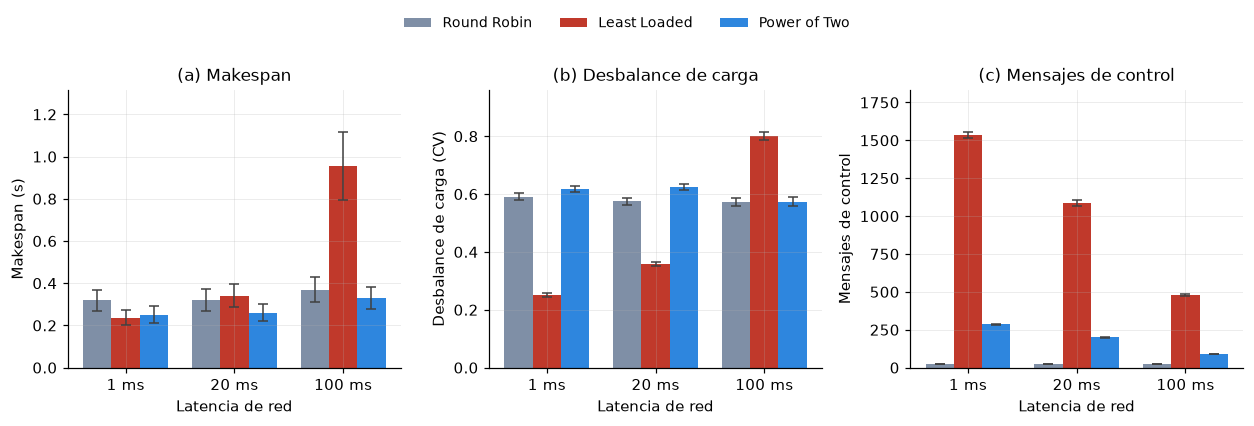

[fig] Guardada: figuras/fig2_estrategias_cluster_real.png


In [6]:
def barras_agrupadas(df: pd.DataFrame, metrica: str, ax, titulo: str) -> None:
    """Barras agrupadas por latencia con barras de error (IC 95%)."""
    ancho = 0.26
    x = np.arange(len(LATENCIAS))
    for i, est in enumerate(ESTRATEGIAS):
        medias, errores = [], []
        for lat in LATENCIAS:
            g = df[(df["strategy"] == est) & (df["latency_ms"] == lat)][metrica].values
            media, half = ic95(g)
            medias.append(media)
            errores.append(half)
        pos = x + (i - 1) * ancho
        ax.bar(pos, medias, width=ancho, yerr=errores, capsize=3,
               color=COLORES[est], label=NOMBRE_ESTRATEGIA[est],
               error_kw={"elinewidth": 1.0, "ecolor": "0.25"})
    ax.set_xticks(x)
    ax.set_xticklabels([f"{int(l)} ms" for l in LATENCIAS])
    ax.set_xlabel("Latencia de red")
    ax.set_ylabel(ETIQUETAS_METRICAS[metrica])
    ax.set_title(titulo)
    ax.margins(y=0.18)  # espacio vertical para no tapar las barras

fig, ejes = plt.subplots(1, 3, figsize=(11.5, 3.6))
barras_agrupadas(df_real, "makespan_s", ejes[0], "(a) Makespan")
barras_agrupadas(df_real, "load_imbalance_cv", ejes[1], "(b) Desbalance de carga")
barras_agrupadas(df_real, "control_messages", ejes[2], "(c) Mensajes de control")
manejadores, rótulos = ejes[0].get_legend_handles_labels()
fig.legend(manejadores, rótulos, loc="upper center", ncol=3,
           bbox_to_anchor=(0.5, 1.08), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(FIG_DIR / "fig2_estrategias_cluster_real.png", bbox_inches="tight")
plt.show()
print(f"[fig] Guardada: figuras/fig2_estrategias_cluster_real.png")


=== Error relativo % (Makespan, Real vs SimGrid) ===
              1 ms  20 ms  100 ms  Error medio (%)
Round Robin   0.44   1.09    0.45             0.73
Least Loaded  2.07   0.59    1.85             1.25
Power of Two  0.33   1.56    1.05             1.55


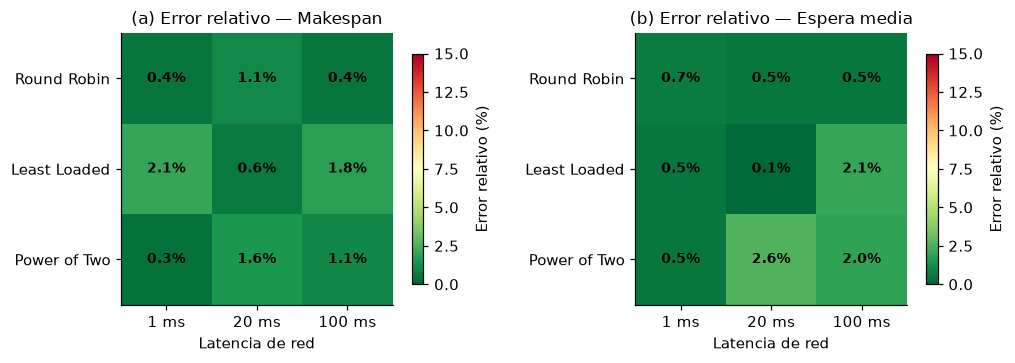

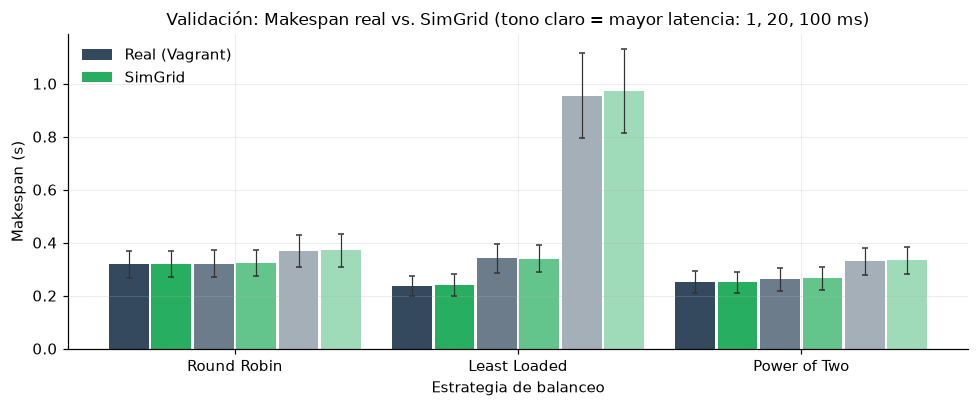

[fig] Guardadas: figuras/fig3a_heatmap_error_validacion.png, figuras/fig3b_real_vs_simgrid_makespan.png


In [7]:
def error_relativo(metrica: str) -> pd.DataFrame:
    """Error relativo % |sim - real| / real, por estrategia y latencia."""
    base = df_real.groupby(["strategy", "latency_ms"])[metrica].mean()
    sim = df_val.groupby(["strategy", "latency_ms"])[metrica].mean()
    err = ((sim - base).abs() / base) * 100
    return err.unstack("latency_ms").reindex(ESTRATEGIAS)[LATENCIAS]


errores = {m: error_relativo(m) for m in METRICAS}
tabla_validacion = errores["makespan_s"].round(2).copy()
tabla_validacion.index = [NOMBRE_ESTRATEGIA[i] for i in tabla_validacion.index]
tabla_validacion.columns = [f"{int(c)} ms" for c in tabla_validacion.columns]
tabla_validacion["Error medio (%)"] = pd.concat(
    [errores[m].mean(axis=1) for m in METRICAS], axis=1).mean(axis=1).reindex(ESTRATEGIAS).round(2).values
print("\n=== Error relativo % (Makespan, Real vs SimGrid) ===")
print(tabla_validacion.to_string())

# Heatmap del error relativo % (makespan y espera media)
fig, ejes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, (metrica, titulo) in zip(
        ejes,
        [("makespan_s", "(a) Error relativo — Makespan"), ("mean_wait_s", "(b) Error relativo — Espera media")]):
    data = errores[metrica].values
    im = ax.imshow(data, cmap="RdYlGn_r", vmin=0, vmax=max(15, np.ceil(data.max())))
    ax.set_xticks(range(len(LATENCIAS)), [f"{int(l)} ms" for l in LATENCIAS])
    ax.set_yticks(range(len(ESTRATEGIAS)), [NOMBRE_ESTRATEGIA[e] for e in ESTRATEGIAS])
    ax.set_xlabel("Latencia de red")
    ax.set_title(titulo)
    ax.grid(False)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data[i, j]:.1f}%", ha="center", va="center", fontsize=9, fontweight="bold")
    fig.colorbar(im, ax=ax, shrink=0.85, label="Error relativo (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3a_heatmap_error_validacion.png", bbox_inches="tight")
plt.show()

# Makespan real vs simulado, lado a lado
# Un grupo por estrategia; dentro de cada grupo, 3 pares (real, sim) por latencia.
fig, ax = plt.subplots(figsize=(9.0, 3.8))
x = np.arange(len(ESTRATEGIAS))
for j, lat in enumerate(LATENCIAS):
    base_grupo = x + (j - 1) * 0.30          # posición del par dentro del grupo
    for k, (dfx, etiqueta, color) in enumerate([
            (df_real, "Real (Vagrant)", "#34495e"),
            (df_val, "SimGrid", "#27ae60")]):
        medias, halfs = [], []
        for est in ESTRATEGIAS:
            g = dfx[(dfx["latency_ms"] == lat) & (dfx["strategy"] == est)]["makespan_s"].values
            media, half = ic95(g)
            medias.append(media)
            halfs.append(half)
        pos = base_grupo + (-0.075 if k == 0 else 0.075)
        alpha = 1.0 - j * 0.28  # tono más claro = mayor latencia
        ax.bar(pos, medias, width=0.14, yerr=halfs, capsize=2, color=color,
               alpha=alpha, label=etiqueta if j == 0 else None,
               error_kw={"elinewidth": 0.8, "ecolor": "0.2"})
ax.set_xticks(x, [NOMBRE_ESTRATEGIA[e] for e in ESTRATEGIAS])
ax.set_xlabel("Estrategia de balanceo")
ax.set_ylabel("Makespan (s)")
ax.set_title("Validación: Makespan real vs. SimGrid (tono claro = mayor latencia: 1, 20, 100 ms)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3b_real_vs_simgrid_makespan.png", bbox_inches="tight")
plt.show()
print(f"[fig] Guardadas: figuras/fig3a_heatmap_error_validacion.png, figuras/fig3b_real_vs_simgrid_makespan.png")


[escala] Saturación de least_loaded detectada en n = 64 nodos (makespan 14.72× el de power_of_two; brecha basal 2.60×)


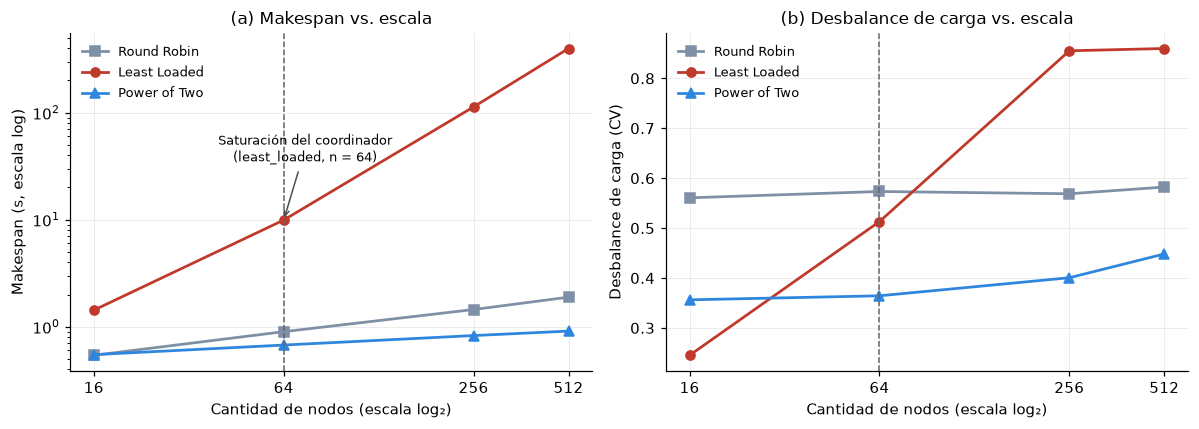

[fig] Guardada: figuras/fig4_extrapolacion_escala.png


In [8]:
def curva_escala(metrica: str) -> dict:
    """Media de la métrica por (estrategia, n_workers), latencia agregada."""
    g = df_scale.groupby(["strategy", "n_workers"])[metrica].mean()
    return {est: g.loc[est].reindex(NODOS).values for est in ESTRATEGIAS}


curvas_mk = curva_escala("makespan_s")
curvas_cv = curva_escala("load_imbalance_cv")

# Punto de inflexión: primer n donde la brecha least_loaded / power_of_two
# supera en 50% la brecha basal observada en n = 16 (cambio de tendencia).
gap = curvas_mk["least_loaded"] / curvas_mk["power_of_two"]
umbral = gap[0] * 1.5
idx_saturacion = next(
    (i for i in range(len(NODOS)) if gap[i] > umbral), len(NODOS) - 1)
n_saturacion = NODOS[idx_saturacion]
print(f"\n[escala] Saturación de least_loaded detectada en n = {n_saturacion} nodos "
      f"(makespan {gap[idx_saturacion]:.2f}× el de power_of_two; brecha basal {gap[0]:.2f}×)")

fig, ejes = plt.subplots(1, 2, figsize=(11.0, 4.0))
marcadores = {"round_robin": "s", "least_loaded": "o", "power_of_two": "^"}
for est in ESTRATEGIAS:
    ejes[0].plot(NODOS, curvas_mk[est], marker=marcadores[est], color=COLORES[est],
                 label=NOMBRE_ESTRATEGIA[est], linewidth=1.8, markersize=6)
    ejes[1].plot(NODOS, curvas_cv[est], marker=marcadores[est], color=COLORES[est],
                 label=NOMBRE_ESTRATEGIA[est], linewidth=1.8, markersize=6)

ejes[0].set_xscale("log", base=2)
ejes[0].set_xticks(NODOS, [str(n) for n in NODOS])
ejes[0].set_xlabel("Cantidad de nodos (escala log₂)")
ejes[0].set_ylabel("Makespan (s, escala log)")
ejes[0].set_yscale("log")
ejes[0].set_title("(a) Makespan vs. escala")
ejes[0].axvline(n_saturacion, color="0.4", linestyle="--", linewidth=1.0)
ejes[0].annotate(
    f"Saturación del coordinador\n(least_loaded, n = {n_saturacion})",
    xy=(n_saturacion, curvas_mk["least_loaded"][idx_saturacion]),
    xytext=(0.45, 0.62), textcoords="axes fraction",
    fontsize=8.5, ha="center",
    arrowprops={"arrowstyle": "->", "color": "0.3", "lw": 1.0})

ejes[1].set_xscale("log", base=2)
ejes[1].set_xticks(NODOS, [str(n) for n in NODOS])
ejes[1].set_xlabel("Cantidad de nodos (escala log₂)")
ejes[1].set_ylabel("Desbalance de carga (CV)")
ejes[1].set_title("(b) Desbalance de carga vs. escala")
ejes[1].axvline(n_saturacion, color="0.4", linestyle="--", linewidth=1.0)

for ax in ejes:
    ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_extrapolacion_escala.png", bbox_inches="tight")
plt.show()
print(f"[fig] Guardada: figuras/fig4_extrapolacion_escala.png")

In [9]:
descriptiva.to_csv(TAB_DIR / "tabla1_descriptiva_cluster_real.csv", index=False)
descriptiva.to_latex(TAB_DIR / "tabla1_descriptiva_cluster_real.tex",
                     float_format="%.4f", index=False, caption="Estadística descriptiva del clúster real (media, DE e IC 95%).",
                     label="tab:descriptiva")

tabla_informe.to_csv(TAB_DIR / "tabla1b_descriptiva_informe.csv", index=False)
tabla_informe.to_latex(TAB_DIR / "tabla1b_descriptiva_informe.tex", index=False,
                       caption="Media ± IC 95% por estrategia y latencia (clúster real).",
                       label="tab:informe", escape=True)

tabla_validacion.to_csv(TAB_DIR / "tabla2_error_validacion.csv")
tabla_validacion.to_latex(TAB_DIR / "tabla2_error_validacion.tex",
                          float_format="%.2f", caption="Error relativo porcentual Real vs. SimGrid (Makespan).",
                          label="tab:validacion")

pd.DataFrame(
    [(NOMBRE_ESTRATEGIA[e], n, curvas_mk[e][i], curvas_cv[e][i])
     for e in ESTRATEGIAS for i, n in enumerate(NODOS)],
    columns=["Estrategia", "Nodos", "Makespan_s", "Desbalance_CV"],
).to_csv(TAB_DIR / "tabla3_escala_resumen.csv", index=False)

print("\n=== Exportación completa ===")
print(f"Figuras → {FIG_DIR}/")
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  • {p.name}")
print(f"Tablas  → {TAB_DIR}/")
for p in sorted(TAB_DIR.glob("*.*")):
    print(f"  • {p.name}")


=== Exportación completa ===
Figuras → /home/zolmex/Documents/Git/cluster-sim/figuras/
  • fig2_estrategias_cluster_real.png
  • fig3a_heatmap_error_validacion.png
  • fig3b_real_vs_simgrid_makespan.png
  • fig4_extrapolacion_escala.png
Tablas  → /home/zolmex/Documents/Git/cluster-sim/tablas/
  • tabla1_descriptiva_cluster_real.csv
  • tabla1_descriptiva_cluster_real.tex
  • tabla1b_descriptiva_informe.csv
  • tabla1b_descriptiva_informe.tex
  • tabla2_error_validacion.csv
  • tabla2_error_validacion.tex
  • tabla3_escala_resumen.csv
